In [1]:
# Import relevant libraries
from os import listdir
import pickle
import warnings
from scipy import stats

#import lightgbm
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
#import sphractal
import xgboost

#from natsort import natsorted
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostRegressor, BaggingRegressor, ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor, StackingRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import ElasticNetCV, LassoLarsCV, LinearRegression, RidgeCV
from sklearn.metrics import explained_variance_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.manifold import TSNE
from sklearn.model_selection import cross_val_score, GridSearchCV, KFold, learning_curve, LearningCurveDisplay, RandomizedSearchCV, RepeatedKFold, ShuffleSplit, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler, PowerTransformer, FunctionTransformer
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.feature_selection import SelectKBest, f_classif
#from sphractal import readInp, findNN
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

from scipy.spatial import ConvexHull
from scipy.spatial.distance import cdist
from sklearn.datasets import make_blobs, make_regression
from mpl_toolkits.mplot3d import Axes3D

from spams import archetypalAnalysis
from sklearn.datasets import load_diabetes, load_linnerud

# Print package versions for reproducibility
print('Versions of imported libraries:')
#print(f"  lightgbm: {lightgbm.__version__}")
print(f"  matplotlib: {mpl.__version__}")
print(f"  numpy: {np.__version__}")
print(f"  pandas: {pd.__version__}")
print(f"  seaborn: {sns.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
#print(f"  sphractal: {sphractal.__version__}")
print(f"  xgboost: {xgboost.__version__}")

Versions of imported libraries:
  matplotlib: 3.7.1
  numpy: 1.24.3
  pandas: 1.5.3
  seaborn: 0.12.2
  scikit-learn: 1.3.0
  xgboost: 2.0.2


### Finally we're gonna apply ML models on archetypes

In [2]:
def load_pickle_data(filename):
    with open(filename, 'rb') as f:
        data = pickle.load(f)
    return data

In [3]:
def extractClosestMatch(Z, X, A):
    close_match = {}
    for i in range(Z.shape[1]):
        r = cdist(X, Z[:, i].reshape(1, X.shape[1]))
        iMin = np.argmin(r)
        close_match[i+1] = (iMin, A[:, iMin])
    return close_match
def getHull(X, NUM_ARCHETYPES, ROBUST):
    Z, A, B = archetypalAnalysis(np.asfortranarray(X.T), p=NUM_ARCHETYPES, returnAB=True, robust=ROBUST, epsilon=0.001, randominit=False)
    Xapprox = np.matmul(Z, A.toarray())
    expVar = explained_variance_score(X, Xapprox.T)
    close_match = extractClosestMatch(Z, X, A)
    idxs = []
    for idx in close_match.values():
        print(idx[0])
        idxs.append(idx[0])
    return idxs

In [4]:
df = load_pickle_data('dataForAndrew2.pickle')
#df = pd.concat([df[0],df[1],df[2]], axis = 0)
df = df[0]
X = df.iloc[:, :-2]
y = df['DBoxEX']

#scaler = MinMaxScaler() # StandardScaler()
#X = scaler.fit_transform(X)
#X = pd.DataFrame(X)


#pt = PowerTransformer(method='yeo-johnson')
#X = pt.fit_transform(X)
#X = pd.DataFrame(X)


# Remove one of each highly correlated feature pairs
CORR_THRESH = 1

corrMat = X.corr()
colsToDrop = []
for (i, col1) in enumerate(X.columns):
    for (j, col2) in enumerate(X.columns):
        if col1 == col2: continue
        if j <= i: continue
        if abs(corrMat.loc[col1][col2]) >= CORR_THRESH:
            if col1 in colsToDrop or col2 in colsToDrop:
                continue
            print(col1, col2, abs(corrMat.loc[col1][col2]))
            colsToDrop.append(col2)
X.drop(colsToDrop, axis=1, inplace=True)
print(f"Total number of features left: {len(X.columns)}")


Perc_BCN_17 Perc_TCN_17 1.000000000000003
Total number of features left: 180


In [5]:
Xtrain, Xtest, yTrain, yTest = train_test_split(X, y, test_size=0.33, random_state=42, shuffle=True, stratify=None)

In [6]:
scaler = StandardScaler()
Xtrain = scaler.fit_transform(Xtrain)
Xtest = scaler.transform(Xtest)

In [7]:
pca = PCA()
pca.fit(Xtrain)
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
print(cumulative_variance)

[0.28310224 0.41717713 0.53469905 0.59297751 0.62849983 0.66040916
 0.68565846 0.70482847 0.72335939 0.74042207 0.7557685  0.77056073
 0.78470641 0.79774749 0.80877292 0.81920334 0.82925093 0.83883128
 0.84809373 0.85686702 0.8648108  0.87251634 0.88011076 0.88746607
 0.89459236 0.90124114 0.90762818 0.9137498  0.91964376 0.92518524
 0.93055183 0.93545029 0.94007361 0.94448383 0.94867642 0.95243885
 0.95589553 0.95925613 0.96236405 0.96526735 0.9677814  0.97021455
 0.97238007 0.97421564 0.97593786 0.97758903 0.9791556  0.98063195
 0.98195782 0.98321203 0.98438732 0.98547785 0.98651233 0.98749481
 0.98843858 0.98933813 0.99016056 0.99091871 0.99163674 0.99231383
 0.99296817 0.99356684 0.9940978  0.99459923 0.99505794 0.99547244
 0.99584844 0.99620108 0.99655125 0.99686877 0.9971162  0.99734195
 0.99754983 0.99774884 0.99793412 0.99809966 0.99824762 0.99838889
 0.9985274  0.99864502 0.99876087 0.9988692  0.99897464 0.99907612
 0.99917331 0.99926381 0.99934922 0.99942261 0.99949333 0.9995

In [18]:
# To reduce the running time, I picked a relatively small n_components

In [8]:
pca = PCA(n_components = 30)
pca.fit(Xtrain)
Xtrain = pca.transform(Xtrain)
Xtest = pca.transform(Xtest)


In [9]:
np.array(yTrain)

array([2.28751187, 2.29185708, 2.31887203, ..., 2.2711783 , 2.32566129,
       2.29487219])

In [10]:
# First try 10% of the training set as archetypes, which takes long time to perform the function
idxs = getHull(Xtrain, 268, False)

RSS FISTA = 28728.118
RSS FISTA = 16396.164
RSS FISTA = 14375.512
RSS AS = 9815.8894
RSS AS = 8417.9756
RSS AS = 7782.5694
RSS AS = 7364.4376
RSS AS = 7097.6364
RSS AS = 6905.4537
RSS AS = 6765.7411
RSS AS = 6665.4611
RSS AS = 6590.4441
RSS AS = 6529.2124
RSS AS = 6463.319
RSS AS = 6355.6583
RSS AS = 6219.9481
RSS AS = 6092.4478
RSS AS = 5902.5539
RSS AS = 5652.2655
RSS AS = 5524.341
RSS AS = 5455.784
RSS AS = 5412.9627
RSS AS = 5388.9592
RSS AS = 5374.0565
RSS AS = 5362.4431
RSS AS = 5352.2333
RSS AS = 5342.2944
RSS AS = 5332.1817
RSS AS = 5321.7818
RSS AS = 5310.9285
RSS AS = 5298.799
RSS AS = 5284.4873
RSS AS = 5266.968
RSS AS = 5245.7459
RSS AS = 5223.3207
RSS AS = 5202.9391
RSS AS = 5185.6127
RSS AS = 5172.1406
RSS AS = 5162.7828
RSS AS = 5157.2032
RSS AS = 5154.263
RSS AS = 5152.344
RSS AS = 5150.8301
RSS AS = 5149.5526
RSS AS = 5148.4522
RSS AS = 5147.5725
RSS AS = 5146.7814
RSS AS = 5146.0502
RSS AS = 5145.3304
RSS AS = 5144.5785
RSS AS = 5143.7988
RSS AS = 5142.9758
RSS AS = 5

KeyboardInterrupt: 

In [30]:
X_hull = Xtrain[idxs]
y_hull = np.array(yTrain)[idxs]
X_hull.shape

(268, 30)

In [32]:
model = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
model.fit(X_hull, y_hull)
model.score(Xtest, yTest)

0.6211857360796125

In [33]:
model = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
model.fit(Xtrain, yTrain)
model.score(Xtest, yTest)

0.6437980459508642

In [ ]:
# We can see that the score of both datasets are very similar

In [ ]:
# More tests

10
RSS FISTA = 133403.77
RSS FISTA = 117042.36
RSS FISTA = 109124.19
RSS AS = 103264.18
RSS AS = 101767.76
RSS AS = 100931.25
RSS AS = 100256.67
RSS AS = 99739.25
RSS AS = 99182.203
RSS AS = 98568.958
RSS AS = 98088.896
RSS AS = 97665.983
RSS AS = 97311.691
RSS AS = 97026.945
RSS AS = 96808.91
RSS AS = 96626.862
RSS AS = 96480.265
RSS AS = 96363.876
RSS AS = 96263.798
RSS AS = 96175.069
RSS AS = 96094.897
RSS AS = 96024.973
RSS AS = 95965.078
RSS AS = 95913.3
RSS AS = 95869.003
RSS AS = 95832.212
RSS AS = 95804.738
RSS AS = 95780.233
RSS AS = 95757.224
RSS AS = 95734.482
RSS AS = 95711.403
RSS AS = 95687.534
RSS AS = 95663.242
RSS AS = 95637.851
RSS AS = 95611.127
RSS AS = 95582.877
RSS AS = 95552.933
RSS AS = 95521.374
RSS AS = 95489.266
RSS AS = 95454.681
RSS AS = 95417.717
RSS AS = 95378.675
RSS AS = 95339.013
RSS AS = 95298.708
RSS AS = 95257.529
RSS AS = 95216.251
RSS AS = 95175.521
RSS AS = 95136.489
RSS AS = 95100.173
RSS AS = 95066.902
RSS AS = 95037.027
RSS AS = 95010.273
RSS 

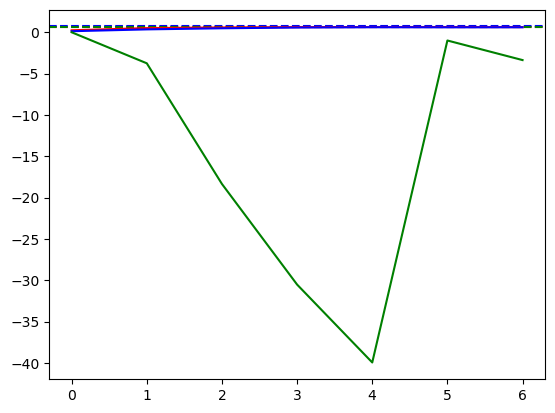

In [110]:
# Run models on the original training set as the baseline
Ridge = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
ExtraTree = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
layers = (129,128,128,129,60,128,60,30)
MLP = MLPRegressor(hidden_layer_sizes=layers,random_state=42, max_iter=40000, alpha=0.1)
Ridge.fit(Xtrain, yTrain)
ExtraTree.fit(Xtrain, yTrain)
MLP.fit(Xtrain, yTrain)
plt.axhline(y = Ridge.score(Xtest, yTest), color = 'r', linestyle = '--')
plt.axhline(y = ExtraTree.score(Xtest, yTest), color = 'b', linestyle = '--')
plt.axhline(y = MLP.score(Xtest, yTest), color = 'g', linestyle = '--')

score_lr = []
score_et = []
score_nn = []
for n_archetype in range(10, 251, 40):
    print(n_archetype)
    idxs = getHull(Xtrain, n_archetype, False)
    X_hull = Xtrain[idxs]
    y_hull = np.array(yTrain)[idxs]
    Ridge.fit(X_hull, y_hull)
    ExtraTree.fit(X_hull, y_hull)
    MLP.fit(X_hull, y_hull)
    score_lr.append(Ridge.score(Xtest, yTest))
    score_et.append(ExtraTree.score(Xtest, yTest))
    score_nn.append(MLP.score(Xtest, yTest))
plt.plot(score_lr, 'r')
plt.plot(score_et, 'b')
plt.plot(score_nn, 'g')
plt.show()

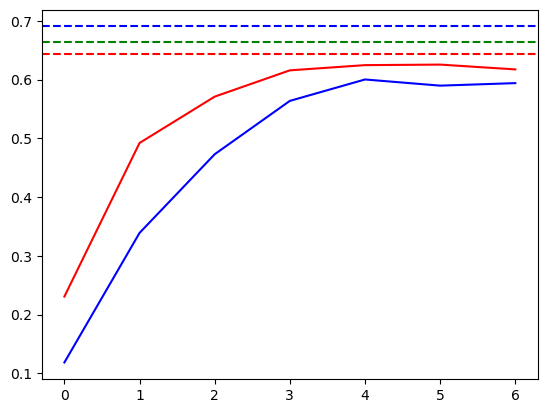

In [112]:
# Since the nn varies too much, let's remove it
Ridge.fit(Xtrain, yTrain)
ExtraTree.fit(Xtrain, yTrain)
MLP.fit(Xtrain, yTrain)
plt.axhline(y = Ridge.score(Xtest, yTest), color = 'r', linestyle = '--')
plt.axhline(y = ExtraTree.score(Xtest, yTest), color = 'b', linestyle = '--')
plt.axhline(y = MLP.score(Xtest, yTest), color = 'g', linestyle = '--')

plt.plot(score_lr, 'r')
plt.plot(score_et, 'b')
plt.show()

In [113]:
# More experiments needed, like more archetypes

200
RSS FISTA = 33154.87
RSS FISTA = 21105.589
RSS FISTA = 18265.546
RSS AS = 12846.179
RSS AS = 10088.941
RSS AS = 8451.075
RSS AS = 7929.5933
RSS AS = 7704.2677
RSS AS = 7543.6976
RSS AS = 7416.5787
RSS AS = 7326.2702
RSS AS = 7247.4034
RSS AS = 7164.2491
RSS AS = 7084.7938
RSS AS = 7018.2234
RSS AS = 6966.7225
RSS AS = 6927.6343
RSS AS = 6892.5982
RSS AS = 6853.5231
RSS AS = 6814.4015
RSS AS = 6786.5438
RSS AS = 6765.7506
RSS AS = 6749.0211
RSS AS = 6734.1663
RSS AS = 6722.2178
RSS AS = 6714.6169
RSS AS = 6709.6249
RSS AS = 6705.2043
RSS AS = 6700.9362
RSS AS = 6696.7481
RSS AS = 6692.6734
RSS AS = 6688.6544
RSS AS = 6684.672
RSS AS = 6680.7492
RSS AS = 6676.9017
RSS AS = 6673.0538
RSS AS = 6669.0471
RSS AS = 6664.8548
RSS AS = 6660.3689
RSS AS = 6655.8517
RSS AS = 6651.0541
RSS AS = 6645.6663
RSS AS = 6639.5138
RSS AS = 6632.9376
RSS AS = 6625.7912
RSS AS = 6618.2
RSS AS = 6610.8972
RSS AS = 6604.0104
RSS AS = 6596.8231
RSS AS = 6589.4495
RSS AS = 6582.4358
RSS AS = 6576.7496
RSS A

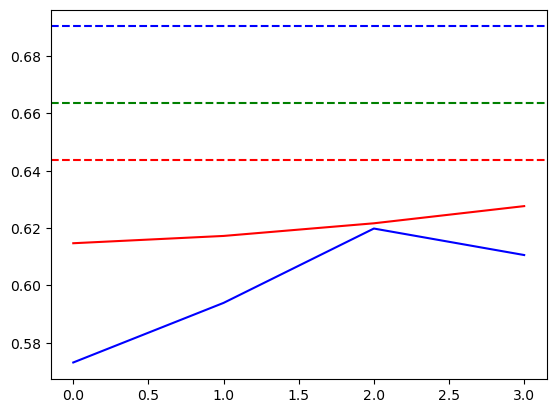

In [116]:
Ridge = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
ExtraTree = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
layers = (129,128,128,129,60,128,60,30)
MLP = MLPRegressor(hidden_layer_sizes=layers,random_state=42, max_iter=40000, alpha=0.1)
Ridge.fit(Xtrain, yTrain)
ExtraTree.fit(Xtrain, yTrain)
MLP.fit(Xtrain, yTrain)
plt.axhline(y = Ridge.score(Xtest, yTest), color = 'r', linestyle = '--')
plt.axhline(y = ExtraTree.score(Xtest, yTest), color = 'b', linestyle = '--')
plt.axhline(y = MLP.score(Xtest, yTest), color = 'g', linestyle = '--')

score_lr = []
score_et = []
score_nn = []
for n_archetype in range(200, 400, 50):
    print(n_archetype)
    idxs = getHull(Xtrain, n_archetype, False)
    X_hull = Xtrain[idxs]
    y_hull = np.array(yTrain)[idxs]
    Ridge.fit(X_hull, y_hull)
    ExtraTree.fit(X_hull, y_hull)
    #MLP.fit(X_hull, y_hull)
    score_lr.append(Ridge.score(Xtest, yTest))
    score_et.append(ExtraTree.score(Xtest, yTest))
    #score_nn.append(MLP.score(Xtest, yTest))
plt.plot(score_lr, 'r')
plt.plot(score_et, 'b')
#plt.plot(score_nn, 'g')
plt.show()